# GIẢI THÍCH SHAP XAI VÀ ĐỀ XUẤT HÀNH ĐỘNG CẢI THIỆN SẢN PHẨM TMĐT

In [1]:
import os, re, joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shap

In [2]:
import sys
ROOT = os.path.abspath('..') if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)
PROC_DIR = os.path.join(ROOT, 'data', 'processed')
MODEL_DIR = os.path.join(ROOT, 'models')
FIG_DIR = os.path.join(ROOT, 'reports', 'figures')
os.makedirs(FIG_DIR, exist_ok=True)

In [3]:
#Nap du lieu huan luyen va ket qua du doan cua mo hinh PhoBERT
df_train = pd.read_csv(os.path.join(PROC_DIR, 'train_clean.csv'))
pred_file = 'test_pred_phobert.csv' if os.path.exists(os.path.join(PROC_DIR, 'test_pred_phobert.csv')) else 'test_pred_baseline.csv'
df_test = pd.read_csv(os.path.join(PROC_DIR, pred_file))
df_test['sentence_clean'] = df_test['sentence_clean'].fillna('')
df_test['sentence_seg'] = df_test['sentence_seg'].fillna('')

In [4]:
df_train.shape, df_test.shape, pred_file

((7776, 16), (2224, 26), 'test_pred_phobert.csv')

## NẠP MÔ HÌNH VÀ KHỞI TẠO SHAP LINEAR EXPLAINER

In [5]:
tfidf = joblib.load(os.path.join(MODEL_DIR, 'tfidf_vectorizer.pkl'))
lr_sent = joblib.load(os.path.join(MODEL_DIR, 'lr_sentiment.pkl'))

In [6]:
#Vector hoa tap train lam background de tranh ro ri du lieu
X_tr = tfidf.transform(df_train['sentence_seg'].fillna(''))
X_te = tfidf.transform(df_test['sentence_seg'].fillna(''))[:400]
# Dung 100 mau train tieu bieu lam background de tinh toan nhanh va chuan xac
explainer = shap.LinearExplainer(lr_sent, shap.sample(X_tr, 100, random_state=42))
shap_vals = explainer.shap_values(X_te)

In [7]:
shap_vals.shape if hasattr(shap_vals, 'shape') else len(shap_vals)

(400, 15000, 3)

## GIẢI THÍCH TOÀN CỤC: TOP TỪ KHÓA ĐẨY VỀ TIÊU CỰC MẠNH NHẤT

In [8]:
vocab = tfidf.get_feature_names_out()
# Lay gia tri SHAP cua nhan tieu cuc (index 0)
neg_shap = shap_vals[:, :, 0] if getattr(shap_vals, 'ndim', 0) == 3 else shap_vals[0]

# Tinh dong gop ve phia Tieu cuc khi tu khoa thuc su xuat hien trong danh gia (loc nhieu count >= 3)
present_mask = (X_te > 0).toarray()
counts = present_mask.sum(axis=0)
shap_when_present = np.where(present_mask, neg_shap, 0.0)
sum_shap = shap_when_present.sum(axis=0)
mean_neg = np.zeros(len(vocab))
mask = counts >= 3
mean_neg[mask] = sum_shap[mask] / counts[mask]
top_idx = np.argsort(mean_neg)[-15:]
print('Top 15 tu khoa day manh nhat ve Tieu cuc khi xuat hien:')
for idx in top_idx[::-1]:
    print(f'  {vocab[idx]}: mean_shap={mean_neg[idx]:.4f}, count={counts[idx]}')

Top 15 tu khoa day manh nhat ve Tieu cuc khi xuat hien:
  thất_vọng: mean_shap=0.3724, count=25
  tệ: mean_shap=0.3030, count=24
  chán: mean_shap=0.2972, count=15
  mau: mean_shap=0.2532, count=4
  không mượt: mean_shap=0.2489, count=4
  mờ: mean_shap=0.2288, count=5
  đơ: mean_shap=0.2214, count=26
  thua: mean_shap=0.2100, count=9
  kém: mean_shap=0.2016, count=22
  yếu: mean_shap=0.1878, count=19
  tụt: mean_shap=0.1857, count=17
  nguồn: mean_shap=0.1775, count=9
  xấu: mean_shap=0.1728, count=12
  lag: mean_shap=0.1723, count=18
  hối_hận: mean_shap=0.1721, count=3


Da luu bieu do vao: D:\E-commerce\reports\figures\shap_top_negative_words.png


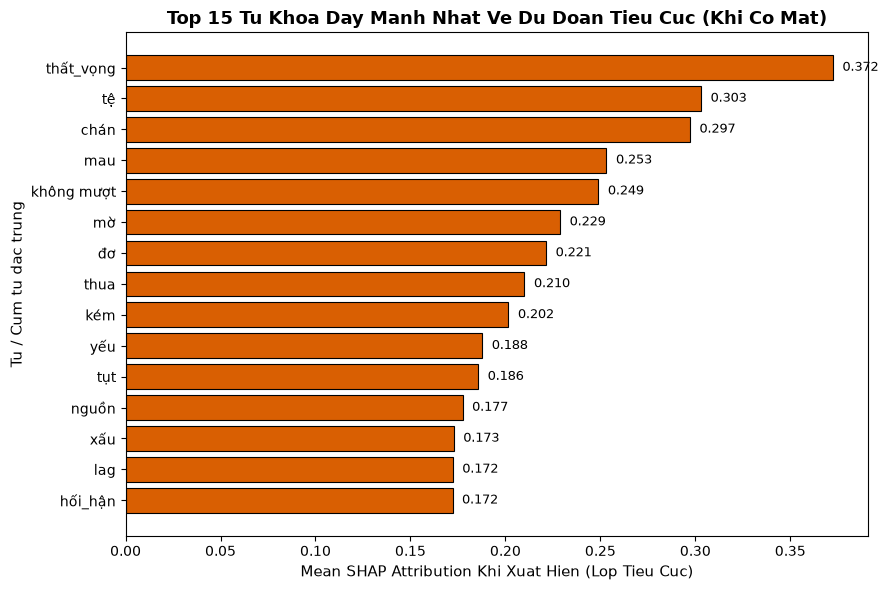

In [9]:
# Ve bieu do Top 15 tu khoa day du doan ve Tieu cuc va luu vao reports/figures/
plt.figure(figsize=(9, 6))
words = [vocab[i] for i in top_idx]
scores = mean_neg[top_idx]
bars = plt.barh(words, scores, color='#d95f02', edgecolor='black', linewidth=0.8)
plt.title('Top 15 Tu Khoa Day Manh Nhat Ve Du Doan Tieu Cuc (Khi Co Mat)', fontsize=13, fontweight='bold')
plt.xlabel('Mean SHAP Attribution Khi Xuat Hien (Lop Tieu Cuc)', fontsize=11)
plt.ylabel('Tu / Cum tu dac trung', fontsize=11)
for bar in bars:
    w = bar.get_width()
    plt.text(w + 0.005, bar.get_y() + bar.get_height()/2, f'{w:.3f}', va='center', fontsize=9)
plt.tight_layout()
os.makedirs(FIG_DIR, exist_ok=True)
fig_path = os.path.join(FIG_DIR, 'shap_top_negative_words.png')
plt.savefig(fig_path, dpi=150)
print('Da luu bieu do vao:', fig_path)
plt.show()

## GIẢI THÍCH CỤC BỘ TỪNG ĐÁNH GIÁ (LOCAL EXPLANATION CHO APP)

In [10]:
#Chon 1 mau danh gia ma ca PhoBERT va LogisticRegression deu du doan la Tieu cuc (0)
neg_cands = df_test[df_test['pred_sentiment'] == 0].copy()
lr_neg_preds = lr_sent.predict(tfidf.transform(neg_cands['sentence_seg']))
tempt_row = neg_cands[lr_neg_preds == 0].iloc[0]
tempt_text = tempt_row['sentence_seg']
tempt_text

'Điện_thoại có 3 lỗi : 1 là chế dô bỏ_túi , 2 là ánh_sáng điện_thoại , 3 là nhấp đúp vào màn_hình thì không nhạy cho lắm , còn lại thì rất tốt'

In [11]:
#Chi loc cac tu co sv_neg_one > 0 (day xac suat ve phia Tieu cuc) va sap xep giam dan theo -x[1]
vec_one = tfidf.transform([tempt_text])
sv_one = explainer.shap_values(vec_one)
sv_neg_one = sv_one[0, :, 0] if getattr(sv_one, 'ndim', 0) == 3 else sv_one[0][0]
nonzero_idx = vec_one.nonzero()[1]
word_imp = sorted([(vocab[i], float(sv_neg_one[i])) for i in nonzero_idx if sv_neg_one[i] > 0], key=lambda x: -x[1])
word_imp[:5]

[('lỗi', 0.1592088584785519),
 ('không nhạy', 0.12633315175631943),
 ('điện_thoại', 0.10520039439432542),
 ('lại', 0.08112871481625276),
 ('ánh_sáng', 0.06588816190839483)]

## ĐỘNG CƠ PHÂN HOẠCH 100% ĐÁNH GIÁ TIÊU CỰC VÀ ĐỀ XUẤT HÀNH ĐỘNG (MECE)

In [12]:
#Loc toan bo danh gia tieu cuc tren tap test
df_neg = df_test[df_test['pred_sentiment'] == 0].copy()
print('tong so danh gia tieu cuc can xu ly: ', len(df_neg))

tong so danh gia tieu cuc can xu ly:  779


In [13]:
df_neg['pred_aspect'].value_counts()

pred_aspect
0    334
2    214
1    129
3     89
4     13
Name: count, dtype: int64

In [14]:
#Bieu thuc chinh quy tach rieng nhom Camera va nhom Man hinh trong aspect 1
cam_pat = r'(?<!\w)(?:chụp|cam|camera|ảnh|quay|mờ|nét|zoom|selfie)(?!\w)'
is_cam = df_neg['sentence_clean'].str.contains(cam_pat, case=False, regex=True, na=False)
int((df_neg['pred_aspect'] == 1).sum()), int(((df_neg['pred_aspect'] == 1) & is_cam).sum()), int(((df_neg['pred_aspect'] == 1) & (~is_cam)).sum())

(129, 113, 16)

In [15]:
#Định nghĩa 6 nhóm giải pháp MECE bao phủ trọn vẹn 100% đánh giá tiêu cực
mece_groups = [
    (0, 'all', 'Hiệu năng & Cấu hình', 'lag, giật, đơ, sóng yếu, phần mềm', 'Tối ưu Hiệu năng, Đa nhiệm & Xử lý Giật Lag: Phát hành bản vá tối ưu quản lý RAM/CPU, kiểm soát xung nhịp và rà soát lỗi kết nối wifi/sóng.'),
    (2, 'all', 'Thời lượng Pin & Sạc', 'tụt pin, hao pin, nóng máy, sạc chậm', 'Cải thiện Thời lượng Pin, Kiểm soát Nhiệt độ & Củ sạc: Rà soát mạch quản lý nguồn, kiểm định bộ sạc kèm máy và tối ưu ứng dụng chạy ngầm.'),
    (1, 'cam', 'Màn hình & Camera - Nhóm Camera', 'chụp mờ, camera, ảnh, quay, zoom', 'Nâng cấp Thuật toán Xử lý Ảnh & Chất lượng Cụm Camera: Tinh chỉnh thuật toán lấy nét/chụp thiếu sáng và kiểm tra chất lượng thấu kính xuất xưởng.'),
    (1, 'scr', 'Màn hình & Camera - Nhóm Màn hình', 'màn hình, cảm ứng, hiển thị, ám, sọc', 'Kiểm soát Chất lượng Tấm nền Hiển thị & Độ nhạy Cảm ứng: Siết chặt QC độ nhạy cảm ứng, tấm nền màn hình và hỗ trợ đổi mới nếu lỗi hiển thị.'),
    (3, 'all', 'Giá cả & Hậu mãi', 'bảo hành, nhân viên, giá, tư vấn, đổi trả', 'Chuẩn hóa Quy trình Bảo hành, CSKH & Chính sách Giá/Hậu mãi: Đào tạo lại thái độ nhân viên, rút ngắn thời gian bảo hành đổi trả và minh bạch ưu đãi.'),
    (4, 'all', 'Thiết kế & Tổng quan', 'thiết kế, vỏ, ngoại quan, phụ kiện, đóng gói', 'Nâng cấp Độ bền Vật liệu Ngoại quan, Phụ kiện & Quy chuẩn Đóng gói: Kiểm tra ngoại quan khung viền/mặt lưng và phụ kiện đi kèm trước khi bàn giao.')
]

In [16]:
# Phan bo doc quyen va day du 100% df_neg vao 6 nhom hanh dong (MECE)
from src.text_cleaner import clean_text
insights = []
for asp_id, mode, cluster_name, kw_str, action_text in mece_groups:
    sub = df_neg[df_neg['pred_aspect'] == asp_id]
    if mode == 'cam': sub = sub[sub['sentence_clean'].str.contains(cam_pat, case=False, regex=True, na=False)]
    elif mode == 'scr': sub = sub[~sub['sentence_clean'].str.contains(cam_pat, case=False, regex=True, na=False)]
    raw_examples = sub['sentence'].head(2).tolist()
    # An danh PII tren cac cau danh gia mau dua vao bao cao
    masked_examples = [clean_text(ex, lowercase=False) for ex in raw_examples]
    insights.append({
        'cluster_id': len(insights)+1,
        'aspect_cluster': cluster_name,
        'negative_count': int(len(sub)),
        'matched_keywords': kw_str,
        'sample_reviews': ' | '.join(masked_examples),
        'recommended_action': action_text
    })
df_insights = pd.DataFrame(insights).sort_values(by='negative_count', ascending=False).reset_index(drop=True)
df_insights['cluster_id'] = range(1, len(df_insights) + 1)

In [17]:
#Kiem chung tong negative_count tren 6 nhom bang dung 100% len(df_neg)
print('tong negative_count 6 nhom: ', int(df_insights['negative_count'].sum()), '| len(df_neg): ', len(df_neg))
assert int(df_insights['negative_count'].sum()) == len(df_neg)

tong negative_count 6 nhom:  779 | len(df_neg):  779


In [18]:
df_insights[['cluster_id', 'aspect_cluster', 'negative_count', 'recommended_action']]

,cluster_id,aspect_cluster,negative_count,recommended_action
0,1,Hiệu năng & Cấu hình,334,"Tối ưu Hiệu năng, Đa nhiệm & Xử lý Giật Lag: P..."
1,2,Thời lượng Pin & Sạc,214,"Cải thiện Thời lượng Pin, Kiểm soát Nhiệt độ &..."
2,3,Màn hình & Camera - Nhóm Camera,113,Nâng cấp Thuật toán Xử lý Ảnh & Chất lượng Cụm...
3,4,Giá cả & Hậu mãi,89,"Chuẩn hóa Quy trình Bảo hành, CSKH & Chính sác..."
4,5,Màn hình & Camera - Nhóm Màn hình,16,Kiểm soát Chất lượng Tấm nền Hiển thị & Độ nhạ...
5,6,Thiết kế & Tổng quan,13,"Nâng cấp Độ bền Vật liệu Ngoại quan, Phụ kiện ..."


## XUẤT BẢNG ĐỀ XUẤT HÀNH ĐỘNG CHO DASHBOARD VÀ APP

In [19]:
out_csv = os.path.join(PROC_DIR, 'actionable_insights.csv')
df_insights.to_csv(out_csv, index=False, encoding='utf-8-sig')
print('da xuat thanh cong: ', out_csv)

da xuat thanh cong:  D:\E-commerce\data\processed\actionable_insights.csv


In [20]:
pd.read_csv(out_csv).shape

(6, 6)